In [82]:
import kagglehub
from pathlib import Path
import random
import os
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pprint import pprint as p
import hashlib
from collections import Counter, defaultdict
import csv
import json
import shutil
import math
# from sklearn.metrics import 
# -------
import ultralytics
from ultralytics import YOLO
import torch
import supervision as sv
import mlflow

In [83]:
path = kagglehub.dataset_download("ahmedsorour1/mri-for-brain-tumor-with-bounding-boxes")
DATA_DIR  = Path(path)
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "pyproject.toml").is_file():
    PROJECT_DIR = PROJECT_DIR.parent
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
CLASSES = [
    "Glioma",
    "Meningioma",
    "No Tumor",
    "Pituitary"
]
YOLO_PATH = PROJECT_DIR / "models" / "best.pt"
extensions = {".jpg", ".jpeg", ".png", ".bmp"}

SEED = 42
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15

NEW_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary",
}

CLASS_MAPPING = {
    0: 0,
    1: 1,
    3: 2,
}

FOLDER_IDS = {
    "Glioma": 0,
    "Meningioma": 1,
    "No Tumor": 2,
    "Pituitary": 3,
}

In [84]:
# Start the MLflow server in a separate terminal first (see docs/MLFLOW.md).
import sys
from time import perf_counter

source_dir = str(PROJECT_DIR / "src")
if source_dir not in sys.path:
    sys.path.insert(0, source_dir)

from neurovision_ai_part3.mlflow_tracking import (
    setup_mlflow,
    log_dataset_artifacts,
    log_yolo_metrics,
    log_yolo_artifacts,
    log_training_results,
    log_environment,
)

setup_mlflow()


MLflow server: file:///C:/Users/Youcode/Documents/DEV_AI/sprint_1/NeuroVision_AI_part3/notebooks/mlruns
Experiment: NeuroVision-YOLOv8


<Experiment: artifact_location='file:///C:/Users/Youcode/Documents/DEV_AI/sprint_1/NeuroVision_AI_part3/notebooks/mlruns/576015267373217325', creation_time=1793359051721, effective_trace_archival_retention=None, experiment_id='576015267373217325', last_update_time=1793359051721, lifecycle_stage='active', name='NeuroVision-YOLOv8', tags={}, trace_location=None, workspace='default'>

In [85]:
def count_files_by_split_and_class(root_path: Path) -> dict:
    existing_class = {
        "Train": {class_name: 0 for class_name in CLASSES},
        "Val": {class_name: 0 for class_name in CLASSES},
    }

    if not root_path.is_dir():
        raise NotADirectoryError(f"Dataset directory not found: {root_path}")

    for file_path in root_path.rglob("*"):
        if not file_path.is_file() or file_path.suffix.lower() not in extensions:
            continue

        relative_parts = file_path.relative_to(root_path).parts
        normalized_parts = [part.lower() for part in relative_parts]

        split = next(
            (name for name in ("Train", "Val") if name.lower() in normalized_parts),
            None,
        )
        class_name = next(
            (name for name in CLASSES if name.lower() in normalized_parts),
            None,
        )

        if split and class_name:
            existing_class[split][class_name] += 1

    return existing_class


existing_class = count_files_by_split_and_class(DATA_DIR)
p(existing_class)

{'Train': {'Glioma': 1153,
           'Meningioma': 1449,
           'No Tumor': 711,
           'Pituitary': 1424},
 'Val': {'Glioma': 136, 'Meningioma': 140, 'No Tumor': 100, 'Pituitary': 136}}


In [86]:
def show_tree(root: Path, max_depth: int = 3, sample_files: int = 5):
    for current_dir, directories, files in os.walk(root):
        current_path = Path(current_dir)
        relative_path = current_path.relative_to(root)
        depth = len(relative_path.parts)

        if depth > max_depth:
            directories[:] = []
            continue

        indent = "    " * depth
        folder_name = root.name if depth == 0 else current_path.name
        print(f"{indent}📁 {folder_name}/")

        for filename in sorted(files)[:sample_files]:
            print(f"{indent}    📄 {filename}")

        remaining = len(files) - sample_files
        if remaining > 0:
            print(f"{indent}    ... {remaining} more files")


show_tree(DATA_DIR)

📁 1/
    📁 Train/
        📁 Glioma/
            📁 images/
                📄 Te-glTr_0000.jpg
                📄 Te-glTr_0005.jpg
                📄 Te-glTr_0007.jpg
                📄 Te-gl_0014.jpg
                📄 Te-gl_0015.jpg
                ... 1148 more files
            📁 labels/
                📄 Te-glTr_0000.txt
                📄 Te-glTr_0005.txt
                📄 Te-glTr_0007.txt
                📄 Te-gl_0014.txt
                📄 Te-gl_0015.txt
                ... 1148 more files
        📁 Meningioma/
            📁 images/
                📄 Tr-meTr_0008.jpg
                📄 Tr-meTr_0009.jpg
                📄 Tr-me_0010.jpg
                📄 Tr-me_0011.jpg
                📄 Tr-me_0017.jpg
                ... 1444 more files
            📁 labels/
                📄 Tr-meTr_0008.txt
                📄 Tr-meTr_0009.txt
                📄 Tr-me_0010.txt
                📄 Tr-me_0011.txt
                📄 Tr-me_0017.txt
                ... 1444 more files
        📁 No Tumor/
          

In [87]:
def inspect_label_samples(
    root_path: Path,
    split: str = "Train",
    samples_per_class: int = 3,
):
    for class_name in CLASSES:
        labels_dir = root_path / split / class_name / "labels"
        label_paths = sorted(labels_dir.glob("*.txt"))

        print(f"\n{class_name}: {len(label_paths)} label files")

        for label_path in label_paths[:samples_per_class]:
            content = label_path.read_text(encoding="utf-8").strip()
            displayed_content = content if content else "<EMPTY>"
            print(f"  {label_path.name}: {displayed_content}")


inspect_label_samples(DATA_DIR)


Glioma: 1153 label files
  gg (1).txt: 0 0.567383 0.519531 0.189453 0.148438
  gg (103).txt: 0 0.414062 0.490234 0.140625 0.132812
  gg (104).txt: 0 0.425781 0.486328 0.191406 0.164062

Meningioma: 1449 label files
  m (10).txt: 1 0.619141 0.471680 0.191406 0.115234
  m (101).txt: 1 0.597656 0.607422 0.105469 0.101562
  m (102).txt: 1 0.383789 0.430664 0.064453 0.177734

No Tumor: 711 label files
  1.txt: 2 0.502857 0.675714 0.851429 0.648571
  3.txt: 2 0.512397 0.513051 0.770248 0.973899
  4.txt: 2 0.525801 0.507601 0.809609 0.984797

Pituitary: 1424 label files
  p (1).txt: 3 0.507812 0.441406 0.093750 0.050781
  p (10).txt: 3 0.512695 0.381836 0.087891 0.072266
  p (100).txt: 3 0.485352 0.615234 0.103516 0.132812


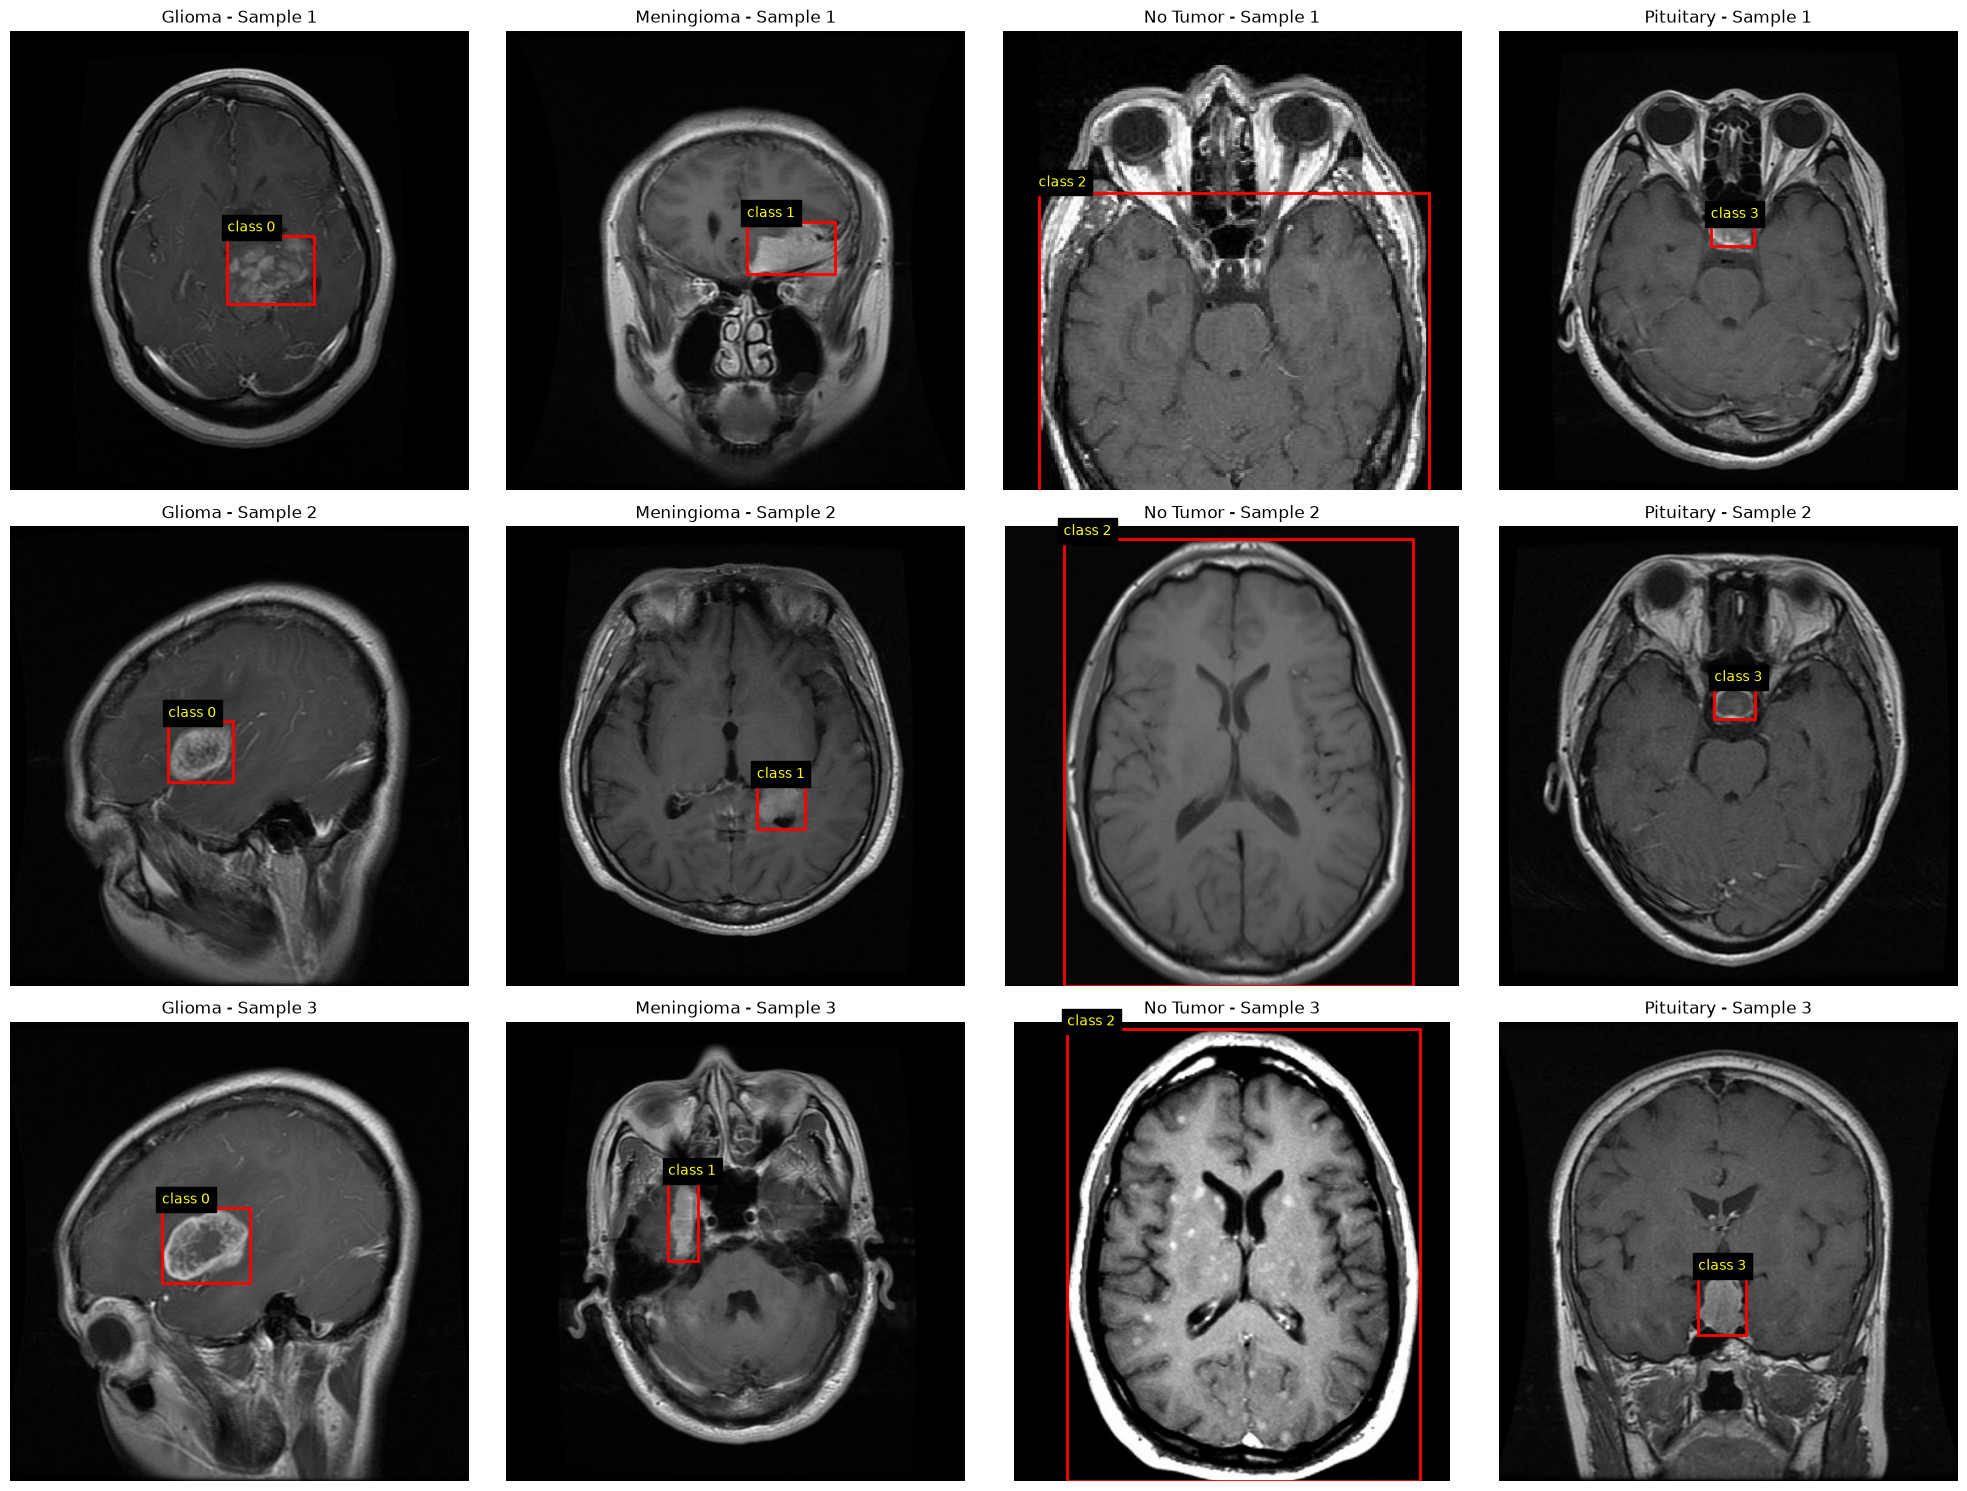

In [88]:
def get_image_paths(root_path: Path, split: str, folder_class: str) -> list[Path]:
    """Get sorted image paths for a specific class."""
    images_dir = root_path / split / folder_class / "images"

    return sorted(
        path for path in images_dir.iterdir()
        if path.is_file() and path.suffix.lower() in extensions
    )


def load_image(image_path: Path):
    """Load an image and convert BGR to RGB."""
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise ValueError(f"Unreadable image: {image_path}")

    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def load_yolo_labels(label_path: Path) -> list[tuple]:
    """Read YOLO annotations: class_id, xc, yc, width, height."""
    labels = []

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        values = list(map(float, line.split()))

        if len(values) != 5:
            raise ValueError(f"Invalid YOLO label in {label_path}: {line}")

        class_id, xc, yc, box_width, box_height = values
        labels.append((int(class_id), xc, yc, box_width, box_height))

    return labels


def draw_bounding_boxes(axis, labels: list[tuple], image_shape: tuple):
    """Convert normalized YOLO coordinates to pixels and draw boxes."""
    image_height, image_width = image_shape[:2]

    for class_id, xc, yc, box_width, box_height in labels:
        x_min = (xc - box_width / 2) * image_width
        y_min = (yc - box_height / 2) * image_height

        rectangle = Rectangle(
            (x_min, y_min),
            box_width * image_width,
            box_height * image_height,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
        axis.add_patch(rectangle)

        axis.text(
            x_min,
            max(0, y_min - 5),
            f"class {class_id}",
            color="yellow",
            fontsize=10,
            backgroundcolor="black",
        )


def plot_sample(axis, image_path: Path, label_path: Path, title: str):
    """Display one image with its YOLO bounding boxes."""
    image = load_image(image_path)
    labels = load_yolo_labels(label_path)

    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")

    draw_bounding_boxes(axis, labels, image.shape)


def show_samples_per_class(
    root_path: Path,
    split: str = "Train",
    num_samples: int = 3,
):
    """Display and save a grid of annotated samples for each class."""
    if num_samples < 1:
        raise ValueError("num_samples must be at least 1")

    fig, axes = plt.subplots(
        num_samples,
        len(CLASSES),
        figsize=(20, 5 * num_samples),
        squeeze=False,
    )

    for col, folder_class in enumerate(CLASSES):
        image_paths = get_image_paths(root_path, split, folder_class)
        labels_dir = root_path / split / folder_class / "labels"

        if len(image_paths) < num_samples:
            raise ValueError(
                f"{folder_class}: requested {num_samples} samples, "
                f"but found {len(image_paths)}"
            )

        for row in range(num_samples):
            image_path = image_paths[row]
            label_path = labels_dir / f"{image_path.stem}.txt"

            plot_sample(
                axis=axes[row, col],
                image_path=image_path,
                label_path=label_path,
                title=f"{folder_class} - Sample {row + 1}",
            )

    plt.tight_layout()

    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    output_path = ARTIFACT_DIR / f"{split.lower()}_samples_grid.png"

    fig.savefig(output_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close(fig)


# Generate one figure with all samples
show_samples_per_class(DATA_DIR, num_samples=3)


# 1. EDA: the remaining checks

The cells above already download the dataset, count images, inspect the
tree and sample labels, and draw 12 MRIs. Here we check file quality,
all annotations, class balance, and leakage. These cells read the raw
Kaggle dataset without changing it.

From the earlier saved run: Val/No Tumor had 2 images without matching
labels and 2 orphan labels. OpenCV found 0 unreadable images. There
were 213 groups of identical images across Train and Val. The earlier
report of 279 invalid rows was too high because it treated every class
different from the folder name as an error; an MRI may have multiple
tumor classes. The corrected check below reports those separately.

## 1.1 Image and label pairs

Equal numbers of images and labels do not prove that names match.
We compare filename stems, count unsupported files, and ask OpenCV
to decode every supported image. We print a few examples of each
problem so they can be investigated before cleaning.

In [89]:
def get_dataset_files(images_dir: Path, labels_dir: Path) -> tuple:
    """Collect image files, supported images, and YOLO labels."""
    files = [path for path in images_dir.iterdir() if path.is_file()]

    images = [
        path for path in files
        if path.suffix.lower() in extensions
    ]

    labels = list(labels_dir.glob("*.txt"))

    return files, images, labels


def check_image_label_pairs(images: list, labels: list) -> dict:
    """Find missing labels, orphan labels, and duplicate image stems."""
    image_stems = {path.stem for path in images}
    label_stems = {path.stem for path in labels}

    return {
        "missing": image_stems - label_stems,
        "orphan": label_stems - image_stems,
        "duplicate_stems": len(images) - len(image_stems),
    }


def check_image_integrity(images: list) -> list:
    """Identify unreadable or corrupted images."""
    broken = []

    for image_path in images:
        try:
            image = cv2.imread(str(image_path))
        except cv2.error:
            image = None

        if image is None:
            broken.append(image_path.name)

    return broken


def build_validation_result(
    split: str,
    class_name: str,
    files: list,
    images: list,
    labels: list,
    pair_check: dict,
    broken: list,
) -> dict:
    """Build a summary of dataset validation metrics."""
    return {
        "split": split,
        "class": class_name,
        "images": len(images),
        "labels": len(labels),
        "missing": len(pair_check["missing"]),
        "orphan": len(pair_check["orphan"]),
        "unsupported": len(files) - len(images),
        "broken": len(broken),
        "duplicate_stems": pair_check["duplicate_stems"],
    }


def print_validation_result(result: dict, pair_check: dict, broken: list):
    """Display validation metrics and examples of detected problems."""
    print(result)

    if pair_check["missing"]:
        print("  Images without labels:", sorted(pair_check["missing"])[:5])

    if pair_check["orphan"]:
        print("  Labels without images:", sorted(pair_check["orphan"])[:5])

    if broken:
        print("  Unreadable images:", broken[:5])


def validate_dataset(
    root_path: Path,
    splits: tuple = ("Train", "Val"),
) -> tuple[list, list]:
    """Validate image-label pairs and image integrity across the dataset."""
    pair_results = []
    all_images = []

    for split in splits:
        for class_name in CLASSES:
            images_dir = root_path / split / class_name / "images"
            labels_dir = root_path / split / class_name / "labels"

            files, images, labels = get_dataset_files(
                images_dir, labels_dir
            )

            pair_check = check_image_label_pairs(images, labels)
            broken = check_image_integrity(images)

            all_images.extend(
                (split, class_name, image_path)
                for image_path in images
            )

            result = build_validation_result(
                split=split,
                class_name=class_name,
                files=files,
                images=images,
                labels=labels,
                pair_check=pair_check,
                broken=broken,
            )

            pair_results.append(result)
            print_validation_result(result, pair_check, broken)

    return pair_results, all_images


# Run dataset validation
pair_results, all_images = validate_dataset(DATA_DIR)


{'split': 'Train', 'class': 'Glioma', 'images': 1153, 'labels': 1153, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Train', 'class': 'Meningioma', 'images': 1449, 'labels': 1449, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Train', 'class': 'No Tumor', 'images': 711, 'labels': 711, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Train', 'class': 'Pituitary', 'images': 1424, 'labels': 1424, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Val', 'class': 'Glioma', 'images': 136, 'labels': 136, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Val', 'class': 'Meningioma', 'images': 140, 'labels': 140, 'missing': 0, 'orphan': 0, 'unsupported': 0, 'broken': 0, 'duplicate_stems': 0}
{'split': 'Val', 'class': 'No Tumor', 'images': 100, 'labels': 100, 'missing': 2, 'orphan': 2, 'u

## 1.2 Check every YOLO annotation

Each non-empty line needs five values: class ID, center x/y, width,
and height. The box must have positive size and stay inside the image.
We count boxes by the ID written in the label. If that ID differs from
the folder name, we report it for review but do not automatically
call it invalid.

In [90]:
SOURCE_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}


def read_label_file(label_path: Path) -> str:
    """Read a YOLO label file using UTF-8."""
    return label_path.read_text(encoding="utf-8").strip()


def parse_yolo_line(line: str) -> tuple:
    """Parse a YOLO annotation into class ID and box coordinates."""
    parts = line.split()

    if len(parts) != 5:
        raise ValueError("Expected 5 values")

    try:
        class_id = int(parts[0])
        x, y, width, height = map(float, parts[1:])
    except ValueError:
        raise ValueError("Invalid number") from None

    return class_id, x, y, width, height


def is_valid_yolo_box(
    class_id: int,
    x: float,
    y: float,
    width: float,
    height: float,
) -> bool:
    """Check class ID, normalized coordinates, and box boundaries."""
    values = (x, y, width, height)

    box_inside = (
        x - width / 2 >= -1e-6
        and x + width / 2 <= 1 + 1e-6
        and y - height / 2 >= -1e-6
        and y + height / 2 <= 1 + 1e-6
    )

    return (
        class_id in SOURCE_NAMES
        and all(math.isfinite(value) for value in values)
        and all(0 <= value <= 1 for value in values)
        and width > 0
        and height > 0
        and box_inside
    )


def validate_label_file(
    label_path: Path,
    split: str,
    folder_class: str,
    box_counts: dict,
    box_areas: dict,
    empty_labels: Counter,
    folder_mismatch: Counter,
    bad_labels: list,
    expected_id: dict,
):
    """Validate every annotation inside a single YOLO label file."""

    try:
        content = read_label_file(label_path)
    except (OSError, UnicodeError) as error:
        bad_labels.append((str(label_path), 0, str(error)))
        return

    if not content:
        empty_labels[(split, folder_class)] += 1
        return

    for line_number, line in enumerate(content.splitlines(), start=1):
        try:
            class_id, x, y, width, height = parse_yolo_line(line)
        except ValueError as error:
            bad_labels.append((str(label_path), line_number, str(error)))
            continue

        if not is_valid_yolo_box(class_id, x, y, width, height):
            bad_labels.append(
                (str(label_path), line_number, "Invalid class or box")
            )
            continue

        box_counts[split][class_id] += 1
        box_areas[class_id].append(width * height)

        if class_id != expected_id[folder_class]:
            folder_mismatch[(split, folder_class, class_id)] += 1


def print_label_validation(
    splits: tuple,
    classes: list,
    box_counts: dict,
    empty_labels: Counter,
    folder_mismatch: Counter,
    bad_labels: list,
):
    """Display annotation statistics and validation problems."""

    for split in splits:
        print(split, "boxes:", {
            SOURCE_NAMES[class_id]: box_counts[split][class_id]
            for class_id in SOURCE_NAMES
        })

        print(split, "empty labels:", {
            name: empty_labels[(split, name)]
            for name in classes
        })

    print("Invalid label lines:", len(bad_labels))

    print("Valid boxes with a class different from their folder:")
    for key, count in folder_mismatch.items():
        print(" ", key, count)

    for problem in bad_labels[:10]:
        print("  Invalid:", problem)


def validate_yolo_dataset(
    root_path: Path,
    splits: tuple = ("Train", "Val"),
    classes: list = None,
) -> dict:
    """Validate YOLO annotations across dataset splits and classes."""

    if classes is None:
        classes = list(SOURCE_NAMES.values())

    expected_id = {
        name: class_id
        for class_id, name in SOURCE_NAMES.items()
    }

    box_counts = {split: Counter() for split in splits}
    box_areas = {class_id: [] for class_id in SOURCE_NAMES}
    empty_labels = Counter()
    folder_mismatch = Counter()
    bad_labels = []

    for split in splits:
        for folder_class in classes:
            labels_dir = root_path / split / folder_class / "labels"

            for label_path in labels_dir.glob("*.txt"):
                validate_label_file(
                    label_path=label_path,
                    split=split,
                    folder_class=folder_class,
                    box_counts=box_counts,
                    box_areas=box_areas,
                    empty_labels=empty_labels,
                    folder_mismatch=folder_mismatch,
                    bad_labels=bad_labels,
                    expected_id=expected_id,
                )

    print_label_validation(
        splits=splits,
        classes=classes,
        box_counts=box_counts,
        empty_labels=empty_labels,
        folder_mismatch=folder_mismatch,
        bad_labels=bad_labels,
    )

    return {
        "box_counts": box_counts,
        "box_areas": box_areas,
        "empty_labels": empty_labels,
        "folder_mismatch": folder_mismatch,
        "bad_labels": bad_labels,
    }


# Execute validation
validation_results = validate_yolo_dataset(
    root_path=DATA_DIR,
    splits=("Train", "Val"),
    classes=CLASSES,
)

# Access results for further EDA
box_counts = validation_results["box_counts"]
box_areas = validation_results["box_areas"]
empty_labels = validation_results["empty_labels"]
folder_mismatch = validation_results["folder_mismatch"]
bad_labels = validation_results["bad_labels"]

Train boxes: {'Glioma': 1349, 'Meningioma': 1482, 'No Tumor': 711, 'Pituitary': 1775}
Train empty labels: {'Glioma': 0, 'Meningioma': 0, 'No Tumor': 0, 'Pituitary': 0}
Val boxes: {'Glioma': 153, 'Meningioma': 142, 'No Tumor': 100, 'Pituitary': 161}
Val empty labels: {'Glioma': 1, 'Meningioma': 0, 'No Tumor': 0, 'Pituitary': 0}
Invalid label lines: 0
Valid boxes with a class different from their folder:
  ('Train', 'Glioma', 3) 152
  ('Train', 'Glioma', 1) 3
  ('Train', 'Meningioma', 3) 103
  ('Train', 'Meningioma', 0) 2
  ('Train', 'Pituitary', 1) 1
  ('Val', 'Glioma', 3) 12
  ('Val', 'Meningioma', 3) 6


## 1.3 Images, boxes, and box sizes

An image can contain several boxes. The first two plots compare
image counts with the actual class IDs in label files. The last plot
shows normalized box area (width times height); the observed No Tumor
boxes are large because they surround the brain.

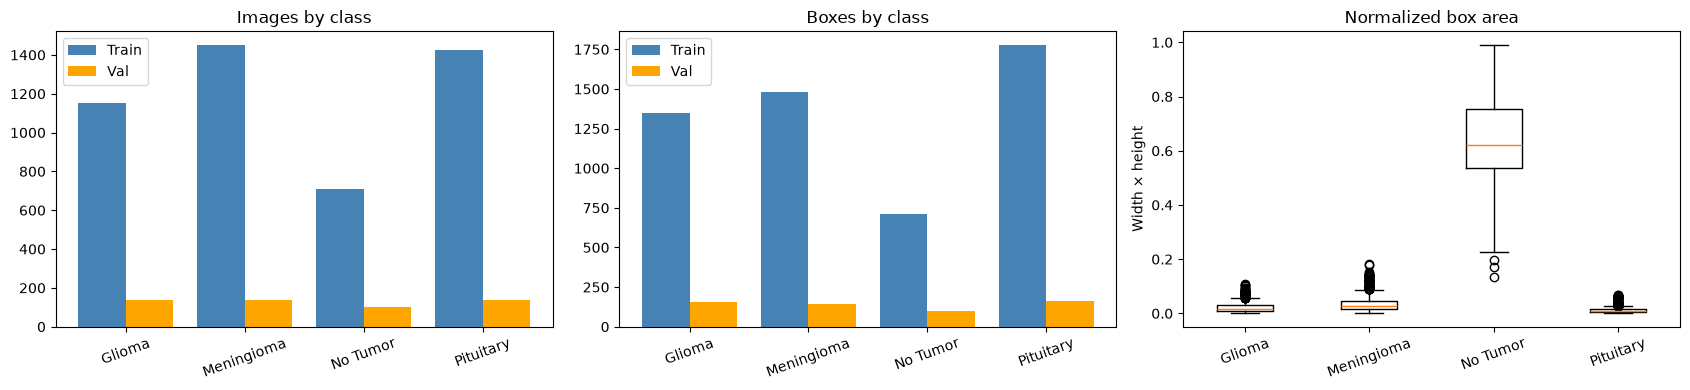

In [91]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
positions = list(range(len(CLASSES)))

for axis, counts, title in (
    (axes[0], existing_class, "Images"),
    (axes[1], box_counts, "Boxes"),
):
    for offset, split, color in (
        (-0.2, "Train", "steelblue"),
        (0.2, "Val", "orange"),
    ):
        if title == "Images":
            values = [counts[split][name] for name in CLASSES]
        else:
            values = [counts[split][class_id] for class_id in SOURCE_NAMES]
        axis.bar(
            [i + offset for i in positions], values,
            width=0.4, label=split, color=color,
        )
    axis.set_xticks(positions, CLASSES, rotation=20)
    axis.set_title(title + " by class")
    axis.legend()

axes[2].boxplot([box_areas[class_id] for class_id in SOURCE_NAMES])
axes[2].set_xticks([1, 2, 3, 4], CLASSES, rotation=20)
axes[2].set_title("Normalized box area")
axes[2].set_ylabel("Width × height")

plt.tight_layout()
fig.savefig(ARTIFACT_DIR / "boxes_and_box_sizes", dpi=300,)
plt.show()

## 1.4 Exact duplicates across splits

Identical files have the same SHA-256 hash even if their names differ.
A copy in both Train and Val makes validation results unreliable.
This check finds exact byte-for-byte copies. It cannot find resized
copies or prove that different images come from different patients.

In [92]:
images_by_hash = {}
splits_by_stem = {}

for split, class_name, image_path in all_images:
    # Only one image is held in memory at a time.
    image_hash = hashlib.sha256(image_path.read_bytes()).hexdigest()
    images_by_hash.setdefault(image_hash, []).append(
        (split, class_name, image_path.name)
    )
    splits_by_stem.setdefault(image_path.stem, set()).add(split)

duplicate_groups = [
    group for group in images_by_hash.values() if len(group) > 1
]
cross_split_groups = [
    group for group in duplicate_groups
    if len({item[0] for item in group}) > 1
]
conflicting_folders = [
    group for group in duplicate_groups
    if len({item[1] for item in group}) > 1
]
shared_stems = [
    stem for stem, found_splits in splits_by_stem.items()
    if len(found_splits) > 1
]

print("Exact duplicate groups:", len(duplicate_groups))
print("Exact groups crossing Train/Val:", len(cross_split_groups))
print("Exact groups in different class folders:", len(conflicting_folders))
print("Filename stems in both splits:", len(shared_stems))
for group in cross_split_groups[:5]:
    print("  Cross-split duplicate:", group)

Exact duplicate groups: 1228
Exact groups crossing Train/Val: 213
Exact groups in different class folders: 0
Filename stems in both splits: 0
  Cross-split duplicate: [('Train', 'Glioma', 'gg (104).jpg'), ('Val', 'Glioma', 'gg (86).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'gg (272).jpg'), ('Train', 'Glioma', 'Tr-glTr_0000.jpg'), ('Val', 'Glioma', 'gg (271).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Te-glTr_0005.jpg'), ('Val', 'Glioma', 'gg (553).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Tr-gl_0010.jpg'), ('Val', 'Glioma', 'gg (312).jpg')]
  Cross-split duplicate: [('Train', 'Glioma', 'Tr-gl_0012.jpg'), ('Val', 'Glioma', 'gg (320).jpg')]


# 2. Preprocessing
Format reference: [Ultralytics detection datasets](https://docs.ultralytics.com/datasets/detect/).
For example, source `3 0.5 0.4 0.1 0.2` becomes
`2 0.5 0.4 0.1 0.2`: the class changes; the box stays the same.

### 2.1 Settings and label conversion

In [93]:



def get_project_dir() -> Path:
    """Resolve the project root from the project or notebooks directory."""
    project_dir = Path.cwd()

    if project_dir.name == "notebooks":
        project_dir = project_dir.parent

    return project_dir.resolve()


def read_label_content(label_path: Path) -> tuple[str, str]:
    """Read annotation content and return an error if unsuccessful."""
    if not label_path.is_file():
        return "", "Missing label"

    try:
        content = label_path.read_text(encoding="utf-8").strip()
    except (OSError, UnicodeError):
        return "", "Unreadable label"

    return content, ""


def parse_label_line(line: str) -> tuple:
    """Convert a YOLO annotation line into numeric values."""
    parts = line.split()

    if len(parts) != 5:
        raise ValueError("Expected five label values")

    try:
        class_id = int(parts[0])
        x, y, width, height = map(float, parts[1:])
    except ValueError:
        raise ValueError("Invalid number in label") from None

    return class_id, x, y, width, height


def validate_bbox(x: float, y: float, width: float, height: float) -> str:
    """Validate normalized YOLO bounding-box coordinates."""
    values = (x, y, width, height)

    if not all(math.isfinite(v) and 0 <= v <= 1 for v in values):
        return "Coordinates must be finite and between 0 and 1"

    if width <= 0 or height <= 0:
        return "Box has zero or negative size"

    if (
        x - width / 2 < -1e-6
        or x + width / 2 > 1 + 1e-6
        or y - height / 2 < -1e-6
        or y + height / 2 > 1 + 1e-6
    ):
        return "Box crosses image boundary"

    return ""


def prepare_label(label_path: Path, folder_class: str) -> tuple[list, str]:
    """Validate and remap YOLO labels into the new three-class format."""
    content, error = read_label_content(label_path)

    if error:
        return [], error

    if not content and folder_class != "No Tumor":
        return [], "Empty label in a tumor folder"

    converted = []

    for line in content.splitlines():
        try:
            class_id, x, y, width, height = parse_label_line(line)
        except ValueError as error:
            return [], str(error)

        error = validate_bbox(x, y, width, height)

        if error:
            return [], error

        if class_id != FOLDER_IDS[folder_class]:
            return [], "Folder/class mismatch: requires annotation review"

        if class_id != 2:
            converted.append((
                CLASS_MAPPING[class_id],
                x, y, width, height
            ))

    return sorted(converted), ""


def validate_preprocessing_config(
    data_dir: Path,
    processed_dir: Path,
    train_ratio: float,
    val_ratio: float,
):
    """Check split ratios and prevent unsafe input/output paths."""
    if not (0 < train_ratio < 1):
        raise ValueError("TRAIN_RATIO must be between 0 and 1")

    if not (0 < val_ratio < 1 - train_ratio):
        raise ValueError("TRAIN_RATIO + VAL_RATIO must be less than 1")

    source = data_dir.resolve()
    destination = processed_dir.resolve()

    if source == destination or source in destination.parents:
        raise ValueError("Output directory must not be inside the source")

    print("Output:", destination)


# Configuration
PROJECT_DIR = get_project_dir()

PROCESSED_DIR = (
    PROJECT_DIR / "data" / "processed" / "neurovision_v1"
).resolve()

validate_preprocessing_config(
    data_dir=DATA_DIR,
    processed_dir=PROCESSED_DIR,
    train_ratio=TRAIN_RATIO,
    val_ratio=VAL_RATIO,
)


Output: C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1


### 2.2 Build the processing list

We need a record for every source image, including rejected ones.
The pixel hash identifies duplicates; a review reason explains why
an image is withheld. Orphan labels are logged separately.
No files are copied in this cell.

In [94]:
def pixel_hash(image):
    """Generate a SHA-256 hash from image dimensions and pixel values."""
    digest = hashlib.sha256(str(image.shape).encode())
    digest.update(image.tobytes())
    return digest.hexdigest()

def get_image_paths(images_dir: Path, extensions: set) -> list[Path]:
    """Collect supported image files from a directory."""

    # TODO: OPTIMIZATION
    # If file ordering is unnecessary, remove sorted() to avoid sorting overhead.
    return [
        path
        for path in sorted(images_dir.iterdir())
        if path.is_file() and path.suffix.lower() in extensions
    ]


def find_orphan_labels(labels_dir: Path, image_stems: Counter) -> list[str]:
    """Find label files without a corresponding image stem."""

    return [
        str(label_path)
        for label_path in sorted(labels_dir.glob("*.txt"))
        if label_path.stem not in image_stems
    ]


def inspect_image(
    image_path: Path,
    label_path: Path,
    folder_class: str,
    image_stems: Counter,
) -> dict:
    """Validate one image-label pair and build its audit record."""

    boxes, reason = prepare_label(label_path, folder_class)

    # TODO: OPTIMIZATION
    # cv2.imread decodes the entire image into memory.
    # For large datasets, process images in batches or use parallel workers.
    try:
        image = cv2.imread(str(image_path))
    except cv2.error:
        image = None

    image_hash = ""

    if image is None:
        reason = "Unreadable image"
    else:
        image_hash = pixel_hash(image)

    # TODO: RELIABILITY
    # Current logic overwrites previous reasons.
    # Consider storing a list of reasons to preserve every detected issue.
    if image_stems[image_path.stem] > 1:
        reason = "Multiple images share the same label stem"

    return {
        "source_split": image_path.parent.parent.parent.name,
        "folder": folder_class,
        "image": image_path,
        "label": label_path,
        "hash": image_hash,
        "boxes": boxes,
        "reason": reason,
        "status": "review" if reason else "pending",
        "new_split": "",
        "destination": "",
    }


def inspect_class_folder(
    folder: Path,
    folder_class: str,
    extensions: set,
) -> tuple[list[dict], list[str]]:
    """Inspect all images and labels belonging to one class."""

    images_dir = folder / "images"
    labels_dir = folder / "labels"

    image_paths = get_image_paths(images_dir, extensions)

    image_stems = Counter(path.stem for path in image_paths)

    orphan_labels = find_orphan_labels(labels_dir, image_stems)

    records = []

    for image_path in image_paths:
        label_path = labels_dir / f"{image_path.stem}.txt"

        record = inspect_image(
            image_path,
            label_path,
            folder_class,
            image_stems,
        )

        records.append(record)

    return records, orphan_labels


def print_audit_summary(records: list[dict], orphan_labels: list[str]) -> None:
    """Display the initial dataset inspection summary."""

    print("Source images:", len(records))
    print("Orphan labels:", len(orphan_labels))
    print(
        "Initial review reasons:",
        Counter(record["reason"] for record in records if record["reason"]),
    )


def audit_dataset(
    data_dir: Path,
    classes: list,
    extensions: set,
    splits: tuple = ("Train", "Val"),
) -> tuple[list[dict], list[str]]:
    """Run the complete dataset inspection."""

    records = []
    orphan_labels = []

    for source_split in splits:
        for folder_class in classes:
            folder = data_dir / source_split / folder_class

            class_records, class_orphans = inspect_class_folder(
                folder,
                folder_class,
                extensions,
            )

            records.extend(class_records)
            orphan_labels.extend(class_orphans)

    assert records, "No source images found; check DATA_DIR."

    print_audit_summary(records, orphan_labels)

    return records, orphan_labels

In [95]:
records, orphan_labels = audit_dataset(
    data_dir=DATA_DIR,
    classes=CLASSES,
    extensions=extensions,
    splits=("Train", "Val"),
)

Source images: 5249
Orphan labels: 2
Initial review reasons: Counter({'Folder/class mismatch: requires annotation review': 272, 'Missing label': 2, 'Empty label in a tumor folder': 1})


### 2.3 Resolve duplicates, then assign splits

An identical image must appear only once. If copies disagree about
their boxes or folder, or any copy needs review, withhold the whole
group. This conservative choice is recorded in the audit. Otherwise,
keep the first copy in a stable order.

Shuffle unique images separately per folder. With 100 unique Glioma
images, 70 go to train, 15 to val, and 15 to test. This preserves
approximately the same folder proportions without oversampling.

In [96]:
def group_images_by_hash(records: list) -> dict:
    """Group image records using their content hashes."""
    groups = {}

    for record in records:
        if record["hash"]:
            groups.setdefault(record["hash"], []).append(record)

    return groups


def has_duplicate_conflict(group: list) -> bool:
    """Check for unresolved annotations or disagreements within a group."""
    first = group[0]

    needs_review = any(record["reason"] for record in group)

    disagreement = any(
        record["folder"] != first["folder"]
        or record["boxes"] != first["boxes"]
        for record in group
    )

    return needs_review or disagreement


def resolve_duplicate_groups(groups: dict) -> list:
    """Keep one representative of each valid duplicate group."""
    unique_images = []

    for image_hash in sorted(groups):
        group = groups[image_hash]
        first = group[0]

        if has_duplicate_conflict(group):
            for record in group:
                record["status"] = "review"

                if not record["reason"]:
                    record["reason"] = (
                        "Duplicate group has conflicting "
                        "or unresolved annotations"
                    )
            continue

        first["status"] = "kept"
        unique_images.append(first)

        for record in group[1:]:
            record["status"] = "duplicate"
            record["destination"] = str(first["image"])

    return unique_images


def split_class_images(
    images: list,
    rng: random.Random,
    train_ratio: float,
    val_ratio: float,
    folder_class: str,
) -> dict:
    """Shuffle and split images from one class into three subsets."""
    images = images.copy()
    rng.shuffle(images)

    train_end = int(len(images) * train_ratio)
    val_end = train_end + int(len(images) * val_ratio)

    if not 0 < train_end < val_end < len(images):
        raise ValueError(f"Too few usable images: {folder_class}")

    return {
        "train": images[:train_end],
        "val": images[train_end:val_end],
        "test": images[val_end:],
    }


def create_stratified_splits(
    unique_images: list,
    classes: list,
    seed: int,
    train_ratio: float,
    val_ratio: float,
) -> dict:
    """Create reproducible splits while preserving source class groups."""
    rng = random.Random(seed)

    processed_splits = {
        "train": [],
        "val": [],
        "test": [],
    }

    for folder_class in classes:
        images = [
            record for record in unique_images
            if record["folder"] == folder_class
        ]

        class_splits = split_class_images(
            images=images,
            rng=rng,
            train_ratio=train_ratio,
            val_ratio=val_ratio,
            folder_class=folder_class,
        )

        for split, split_images in class_splits.items():
            processed_splits[split].extend(split_images)

    return processed_splits


def print_split_summary(records: list, processed_splits: dict):
    """Display record decisions and image counts per split."""
    print("Decisions:", Counter(
        record["status"] for record in records
    ))
    for split, images in processed_splits.items():
        counts = Counter(record["folder"] for record in images)
        print(split, "images by source folder:", dict(counts))


def prepare_dataset_splits(
    records: list,
    classes: list,
    seed: int = 42,
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
) -> tuple:
    """Deduplicate records and create train/val/test splits."""
    groups = group_images_by_hash(records)

    unique_images = resolve_duplicate_groups(groups)

    processed_splits = create_stratified_splits(
        unique_images=unique_images,
        classes=classes,
        seed=seed,
        train_ratio=train_ratio,
        val_ratio=val_ratio,
    )

    print_split_summary(records, processed_splits)

    return processed_splits, unique_images

# Run the preprocessing workflow
processed_splits = prepare_dataset_splits(
    records=records,
    classes=CLASSES,
    seed=SEED,
    train_ratio=TRAIN_RATIO,
    val_ratio=VAL_RATIO,
)

Decisions: Counter({'kept': 2625, 'review': 2406, 'duplicate': 218})
train images by source folder: {'Glioma': 667, 'Meningioma': 396, 'No Tumor': 414, 'Pituitary': 359}
val images by source folder: {'Glioma': 143, 'Meningioma': 84, 'No Tumor': 88, 'Pituitary': 76}
test images by source folder: {'Glioma': 144, 'Meningioma': 86, 'No Tumor': 90, 'Pituitary': 78}


### 2.4 Write the YOLO dataset and reports

YOLO pairs `images/train/example.jpg` with `labels/train/example.txt`.
Use the full pixel hash as the filename to avoid name collisions.
Images are copied without changing their pixels. Every kept image
gets a label file, including an empty file for a negative.

The output folder must be new. To make another version, change
`neurovision_v1` in settings and rerun preprocessing in order.
`audit.csv` lists every source image and orphan label; `manifest.csv`
lists only exported pairs. Review files stay in the raw download.

In [97]:
# if PROCESSED_DIR.exists():
    # raise FileExistsError('Output already exists. Choose a new version in settings.')
# PROCESSED_DIR.mkdir(parents=True)
def write_yolo_label(label_path: Path, boxes: list) -> int:
    """Write YOLO bounding-box annotations to a text file."""
    lines = [
        f"{class_id} {x} {y} {width} {height}"
        for class_id, x, y, width, height in boxes
    ]

    content = "\n".join(lines)

    if lines:
        content += "\n"

    label_path.write_text(content, encoding="utf-8")

    return len(lines)


def export_image_record(
    record: dict,
    split: str,
    processed_dir: Path,
) -> dict:
    """Copy one image, write its labels, and return a manifest entry."""
    image_dir = processed_dir / "images" / split
    label_dir = processed_dir / "labels" / split

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    name = record["hash"]
    image_path = image_dir / (name + record["image"].suffix.lower())
    label_path = label_dir / (name + ".txt")

    shutil.copy2(record["image"], image_path)

    box_count = write_yolo_label(label_path, record["boxes"])

    record["new_split"] = split
    record["destination"] = image_path.relative_to(
        processed_dir
    ).as_posix()

    return {
        "split": split,
        "folder": record["folder"],
        "source": str(record["image"]),
        "pixel_hash": name,
        "image": record["destination"],
        "label": label_path.relative_to(processed_dir).as_posix(),
        "boxes": box_count,
    }


def export_split_images(
    processed_splits: dict,
    processed_dir: Path,
) -> list:
    """Export all split images and collect manifest entries."""
    manifest = []

    for split, images in processed_splits.items():
        for record in images:
            entry = export_image_record(
                record=record,
                split=split,
                processed_dir=processed_dir,
            )
            manifest.append(entry)

    return manifest


def write_data_yaml(
    processed_dir: Path,
    class_names: dict,
):
    """Generate the Ultralytics YOLO dataset configuration."""
    yaml_text = (
        "path: " + json.dumps(processed_dir.as_posix()) + "\n"
    )

    yaml_text += (
        "train: images/train\n"
        "val: images/val\n"
        "test: images/test\n"
        "names:\n"
    )

    for class_id, name in class_names.items():
        yaml_text += f"  {class_id}: {json.dumps(name)}\n"

    (processed_dir / "data.yaml").write_text(
        yaml_text,
        encoding="utf-8",
    )


def build_audit_report(records: list, orphan_labels: list) -> list:
    """Create an audit trail for every processed and rejected record."""
    audit = []

    for record in records:
        audit.append({
            "image": str(record["image"]),
            "label": str(record["label"]),
            "source_split": record["source_split"],
            "folder": record["folder"],
            "pixel_hash": record["hash"],
            "status": record["status"],
            "reason": record["reason"],
            "new_split": record["new_split"],
            "destination": record["destination"],
        })

    for label_path in orphan_labels:
        audit.append({
            "image": "",
            "label": str(label_path),
            "source_split": "",
            "folder": "",
            "pixel_hash": "",
            "status": "review",
            "reason": "Orphan label",
            "new_split": "",
            "destination": "",
        })

    return audit


def write_csv_report(
    output_path: Path,
    rows: list,
    fieldnames: list,
):
    """Write a CSV report, including its header when rows are empty."""
    with output_path.open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(file, fieldnames=fieldnames)
        writer.writeheader()
        writer.writerows(rows)


def export_yolo_dataset(
    processed_splits: dict,
    records: list,
    orphan_labels: list,
    processed_dir: Path,
    class_names: dict,
) -> tuple[list, list]:
    """Export a YOLO dataset, YAML configuration, and audit reports."""
    processed_dir.mkdir(parents=True, exist_ok=True)

    manifest = export_split_images(
        processed_splits=processed_splits,
        processed_dir=processed_dir,
    )

    write_data_yaml(
        processed_dir=processed_dir,
        class_names=class_names,
    )

    audit = build_audit_report(records, orphan_labels)

    write_csv_report(
        processed_dir / "manifest.csv",
        manifest,
        fieldnames=[
            "split", "folder", "source", "pixel_hash",
            "image", "label", "boxes",
        ],
    )

    write_csv_report(
        processed_dir / "audit.csv",
        audit,
        fieldnames=[
            "image", "label", "source_split", "folder",
            "pixel_hash", "status", "reason",
            "new_split", "destination",
        ],
    )

    print("Dataset and reports written to:", processed_dir)

    return manifest, audit


# Execute dataset export
manifest, audit = export_yolo_dataset(
    processed_splits=processed_splits[0],
    records=records,
    orphan_labels=orphan_labels,
    processed_dir=PROCESSED_DIR,
    class_names={
    0: "Glioma",
    1: "Meningioma",
    2: "Pituitary",
})

Dataset and reports written to: C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1


### 2.5 Verify the saved dataset

Read the copied files back from disk: check pairs, pixels, labels,
and hashes across all splits. This is a data integrity check; test
is not used to choose any model or threshold. Save counts and the
split policy in `preprocessing_summary.json`.

After running, inspect `audit.csv` and the printed counts. An image
marked `review` has been withheld, not repaired. We can reconsider
it later with reliable annotation evidence.

In [98]:
def validate_split_structure(
    processed_dir: Path,
    split: str,
    split_rows: list,
) -> list:
    """Verify image-label pairing and manifest counts."""
    image_dir = processed_dir / "images" / split
    label_dir = processed_dir / "labels" / split

    images = sorted(
        path for path in image_dir.iterdir() if path.is_file()
    )
    labels = list(label_dir.glob("*.txt"))

    image_stems = {path.stem for path in images}
    label_stems = {path.stem for path in labels}

    if image_stems != label_stems:
        raise ValueError(f"Image-label mismatch in {split}")

    if len(images) != len(split_rows):
        raise ValueError(f"Manifest count mismatch in {split}")

    return images


def validate_output_image(
    image_path: Path,
    expected_hash: str,
    seen_hashes: set,
) -> str:
    """Verify readability, pixel hash, and cross-split uniqueness."""
    image = cv2.imread(str(image_path))

    if image is None:
        raise ValueError(f"Unreadable output: {image_path}")

    image_hash = pixel_hash(image)

    if image_hash != expected_hash:
        raise ValueError(f"Image hash changed: {image_path}")

    if image_hash in seen_hashes:
        raise ValueError(f"Duplicate image in processed data: {image_path}")

    seen_hashes.add(image_hash)

    return image_hash


def validate_saved_boxes(
    content: str,
    expected_class_id: int,
) -> list:
    """Parse and validate saved YOLO bounding boxes."""
    saved_boxes = []

    for line in content.splitlines():
        parts = line.split()

        if len(parts) != 5:
            raise ValueError("Expected five YOLO label values")

        try:
            class_id = int(parts[0])
            x, y, width, height = map(float, parts[1:])
        except ValueError:
            raise ValueError("Invalid numeric YOLO annotation") from None

        if class_id != expected_class_id:
            raise ValueError("Incorrect processed class ID")

        values = (x, y, width, height)

        if not all(math.isfinite(v) and 0 <= v <= 1 for v in values):
            raise ValueError("Invalid normalized coordinates")

        if width <= 0 or height <= 0:
            raise ValueError("Invalid bounding-box dimensions")

        if not (
            -1e-6 <= x - width / 2
            and x + width / 2 <= 1 + 1e-6
            and -1e-6 <= y - height / 2
            and y + height / 2 <= 1 + 1e-6
        ):
            raise ValueError("Bounding box crosses image boundary")

        saved_boxes.append((class_id, x, y, width, height))

    return saved_boxes


def validate_output_record(
    row: dict,
    processed_dir: Path,
    expected_boxes: dict,
    seen_hashes: set,
    folder_ids: dict,
    class_mapping: dict,
) -> list:
    """Validate one exported image and its saved annotations."""
    image_path = processed_dir / row["image"]
    label_path = processed_dir / row["label"]

    image_hash = validate_output_image(
        image_path=image_path,
        expected_hash=row["pixel_hash"],
        seen_hashes=seen_hashes,
    )

    content = label_path.read_text(encoding="utf-8").strip()

    if row["folder"] == "No Tumor":
        if content:
            raise ValueError(f"Negative image has boxes: {label_path}")

        saved_boxes = []

    else:
        if not content:
            raise ValueError(f"Tumor image has an empty label: {label_path}")

        new_id = class_mapping[folder_ids[row["folder"]]]

        saved_boxes = validate_saved_boxes(
            content=content,
            expected_class_id=new_id,
        )

    if sorted(saved_boxes) != expected_boxes[image_hash]:
        raise ValueError(f"Saved boxes changed: {label_path}")

    if len(content.splitlines()) != row["boxes"]:
        raise ValueError(f"Box count mismatch: {label_path}")

    return saved_boxes


def validate_processed_split(
    processed_dir: Path,
    split: str,
    manifest: list,
    expected_boxes: dict,
    seen_hashes: set,
    folder_ids: dict,
    class_mapping: dict,
    new_names: dict,
) -> dict:
    """Validate an entire exported split and calculate its statistics."""
    split_rows = [
        row for row in manifest if row["split"] == split
    ]

    images = validate_split_structure(
        processed_dir=processed_dir,
        split=split,
        split_rows=split_rows,
    )

    counts = Counter()
    negatives = 0

    for row in split_rows:
        saved_boxes = validate_output_record(
            row=row,
            processed_dir=processed_dir,
            expected_boxes=expected_boxes,
            seen_hashes=seen_hashes,
            folder_ids=folder_ids,
            class_mapping=class_mapping,
        )

        if row["folder"] == "No Tumor":
            negatives += 1

        for class_id, *_ in saved_boxes:
            counts[new_names[class_id]] += 1

    return {
        "images": len(images),
        "negatives": negatives,
        "images_by_source_folder": dict(
            Counter(row["folder"] for row in split_rows)
        ),
        "boxes_by_class": {
            name: counts[name] for name in new_names.values()
        },
    }


def build_preprocessing_report(
    records: list,
    orphan_labels: list,
    summary: dict,
    data_dir: Path,
    seed: int,
    train_ratio: float,
    val_ratio: float,
    class_mapping: dict,
    new_names: dict,
) -> dict:
    """Build a reproducible preprocessing and integrity report."""
    return {
        "seed": seed,
        "source": str(data_dir.resolve()),
        "ratios": {
            "train": train_ratio,
            "val": val_ratio,
            "test": 1 - train_ratio - val_ratio,
        },
        "class_mapping": class_mapping,
        "names": new_names,
        "negative_policy": (
            "Paired No Tumor images become empty labels"
        ),
        "review_policy": (
            "Withhold unresolved annotations "
            "and conflicting duplicate groups"
        ),
        "source_images": len(records),
        "decisions": dict(
            Counter(record["status"] for record in records)
        ),
        "orphan_labels": len(orphan_labels),
        "review_reasons": dict(
            Counter(
                record["reason"]
                for record in records
                if record["status"] == "review"
            )
        ),
        "split_method": (
            "Seeded shuffle within each source folder "
            "after pixel deduplication"
        ),
        "limitation": (
            "Patient overlap and near duplicates remain unverified"
        ),
        "augmentation_applied": False,
        "integrity_checks_passed": True,
        "splits": summary,
    }


def validate_processed_dataset(
    processed_dir: Path,
    processed_splits: dict,
    unique_images: list,
    manifest: list,
    records: list,
    orphan_labels: list,
    data_dir: Path,
    seed: int,
    train_ratio: float,
    val_ratio: float,
    folder_ids: dict,
    class_mapping: dict,
    new_names: dict,
) -> dict:
    """Run final integrity checks and save the preprocessing report."""
    expected_boxes = {
        record["hash"]: record["boxes"]
        for record in unique_images
    }

    seen_hashes = set()
    summary = {}

    for split in processed_splits:
        summary[split] = validate_processed_split(
            processed_dir=processed_dir,
            split=split,
            manifest=manifest,
            expected_boxes=expected_boxes,
            seen_hashes=seen_hashes,
            folder_ids=folder_ids,
            class_mapping=class_mapping,
            new_names=new_names,
        )

    if len(seen_hashes) != len(unique_images):
        raise ValueError("Processed unique image count mismatch")

    report = build_preprocessing_report(
        records=records,
        orphan_labels=orphan_labels,
        summary=summary,
        data_dir=data_dir,
        seed=seed,
        train_ratio=train_ratio,
        val_ratio=val_ratio,
        class_mapping=class_mapping,
        new_names=new_names,
    )

    report_path = processed_dir / "preprocessing_summary.json"

    report_path.write_text(
        json.dumps(report, indent=2),
        encoding="utf-8",
    )

    print(json.dumps(summary, indent=2))
    print("Integrity checks passed. YAML:", processed_dir / "data.yaml")

    return report


# Execute final validation
report = validate_processed_dataset(
    processed_dir=PROCESSED_DIR,
    processed_splits=processed_splits[0],
    unique_images=processed_splits[1],
    manifest=manifest,
    records=records,
    orphan_labels=orphan_labels,
    data_dir=DATA_DIR,
    seed=42,
    train_ratio=0.70,
    val_ratio=0.15,
    folder_ids={
        "Glioma": 0,
        "Meningioma": 1,
        "No Tumor": 2,
        "Pituitary": 3,
    },
    class_mapping={
        0: 0,
        1: 1,
        3: 2,
    },
    new_names={
        0: "Glioma",
        1: "Meningioma",
        2: "Pituitary",
    },
)


{
  "train": {
    "images": 1836,
    "negatives": 414,
    "images_by_source_folder": {
      "Glioma": 667,
      "Meningioma": 396,
      "No Tumor": 414,
      "Pituitary": 359
    },
    "boxes_by_class": {
      "Glioma": 768,
      "Meningioma": 402,
      "Pituitary": 375
    }
  },
  "val": {
    "images": 391,
    "negatives": 88,
    "images_by_source_folder": {
      "Glioma": 143,
      "Meningioma": 84,
      "No Tumor": 88,
      "Pituitary": 76
    },
    "boxes_by_class": {
      "Glioma": 166,
      "Meningioma": 86,
      "Pituitary": 80
    }
  },
  "test": {
    "images": 398,
    "negatives": 90,
    "images_by_source_folder": {
      "Glioma": 144,
      "Meningioma": 86,
      "No Tumor": 90,
      "Pituitary": 78
    },
    "boxes_by_class": {
      "Glioma": 168,
      "Meningioma": 89,
      "Pituitary": 87
    }
  }
}
Integrity checks passed. YAML: C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1\data.yaml


### Track the verified dataset

This separate run saves `data.yaml`, the manifest, audit and summary. It does
not copy the MRI dataset or rerun preprocessing. The console summary above
stays independent of MLflow. The setup cell must have connected to the server.


In [99]:
with mlflow.start_run(run_name="preprocessing_neurovision_v1"):
    mlflow.set_tag("stage", "preprocessing")
    mlflow.log_params({
        "split_seed": report["seed"],
        "train_ratio": report["ratios"]["train"],
        "val_ratio": report["ratios"]["val"],
    })
    log_dataset_artifacts(PROCESSED_DIR)


# model training


In [100]:
# Optional: uncomment this block only when you want a NEW GPU training run.
# The existing training settings are preserved.
# with mlflow.start_run(run_name="yolov8m_training") as run:
#     mlflow.set_tag("stage", "training")
#     log_environment()
#     log_dataset_artifacts(PROCESSED_DIR)
#     model = YOLO('yolov8m.pt')
#     start = perf_counter()
#     results = model.train(
#         data=str(PROCESSED_DIR / "data.yaml"),
#         epochs=100,
#         imgsz=640,
#         batch=-1,
#         device=0,
#         workers=4,
#         patience=15,
#         amp=True,
#     )
#     mlflow.log_metric("training_seconds", perf_counter() - start)
#     log_training_results(model.trainer.save_dir)
#     log_yolo_metrics(results, split="val")
#     print("Training run ID:", run.info.run_id)


In [101]:
try:
    if not PROJECT_DIR.exists:
        raise NameError("Path dosn't exist")
except NameError:
        PROCESSED_DIR = Path().cwd() / "workspace" / "data"

In [102]:
with mlflow.start_run(run_name="yolov8m_validation") as run:
    mlflow.set_tags({"stage": "validation", "evaluation_split": "val"})
    mlflow.log_params({"imgsz": 640, "batch": 16, "device": "cpu", "split": "val"})
    log_environment()
    log_dataset_artifacts(PROCESSED_DIR)
    model = YOLO(str(YOLO_PATH))
    # A unique name lets us upload exactly this validation's output folder.
    validation_name = "baseline_" + run.info.run_id
    start = perf_counter()
    metrics = model.val(
        data=str(PROCESSED_DIR / "data.yaml"),
        split="val",
        imgsz=640,
        batch=16,
        device="cpu",
        plots=True,
        project=str(ARTIFACT_DIR / "validation"),
        name=validation_name,
        exist_ok=True,
    )
    mlflow.log_metric("validation_seconds", perf_counter() - start)
    log_yolo_metrics(metrics, split="val")
    log_yolo_artifacts(
        ARTIFACT_DIR / "validation" / validation_name,
        checkpoint=YOLO_PATH,
    )
    print("Validation run ID:", run.info.run_id)


Ultralytics 8.4.193  Python-3.11.9 torch-2.15.0+cpu CPU (11th Gen Intel Core i5-1135G7 @ 2.40GHz)
Model summary (fused): 92 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 145.1±36.1 MB/s, size: 23.7 KB)
val: Scanning C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1\labels\val... 391 images, 88 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 391/391 893.1it/s 0.4s0.0s
val: New cache created: C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1\labels\val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 9.3s/it 3:538.1ss
                   all        391        332      0.924      0.848      0.933      0.722
                Glioma        143        166      0.918      0.723      0.867      0.656
            Meningioma         84         86       0.94      0.908      0.973      0.804

In [103]:
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@50:", metrics.box.map50)
print("mAP@75:", metrics.box.map75)
print("mAP@50-95:", metrics.box.map)

print("Per-class mAP:", metrics.box.maps)

Precision: 0.9236381086256826
Recall: 0.8476333176817993
mAP@50: 0.9325285434507723
mAP@75: 0.8335022589840865
mAP@50-95: 0.7216651103275971
Per-class mAP: [    0.65628      0.8044     0.70432]


In [104]:
test_metrics = model.val(
    data=str(PROCESSED_DIR / "data.yaml"),
    split="test",
    imgsz=640,
    device='cpu',
    plots=True,
)

Ultralytics 8.4.193  Python-3.11.9 torch-2.15.0+cpu CPU (11th Gen Intel Core i5-1135G7 @ 2.40GHz)
Model summary (fused): 92 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 177.7±66.7 MB/s, size: 19.8 KB)
val: Scanning C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1\labels\test... 398 images, 90 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 398/398 1.5Kit/s 0.3s<0.1s
val: New cache created: C:\Users\Youcode\Documents\DEV_AI\sprint_1\NeuroVision_AI_part3\data\processed\neurovision_v1\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 8.4s/it 3:317.9ss
                   all        398        344      0.875      0.807      0.896      0.671
                Glioma        144        168      0.922      0.701      0.852      0.653
            Meningioma         86         89      0.906      0.863      0.934      0.7

In [105]:
print("Precision:", test_metrics.box.mp)
print("Recall:", test_metrics.box.mr)
print("mAP@50:", test_metrics.box.map50)
print("mAP@75:", test_metrics.box.map75)
print("mAP@50-95:", test_metrics.box.map)

print("Per-class mAP:", test_metrics.box.maps)

Precision: 0.8748690340241838
Recall: 0.807397249687592
mAP@50: 0.8961630926962667
mAP@75: 0.7668244083740032
mAP@50-95: 0.670590996035848
Per-class mAP: [    0.65296     0.74856     0.61026]


In [106]:
for i, class_id in enumerate(test_metrics.box.ap_class_index):
    class_name = model.names[int(class_id)]

    print(f"\nClass: {class_name}")
    print(f"Precision: {test_metrics.box.p[i]:.4f}")
    print(f"Recall: {test_metrics.box.r[i]:.4f}")
    print(f"mAP@50: {test_metrics.box.ap50[i]:.4f}")
    print(f"mAP@50-95: {test_metrics.box.ap[i]:.4f}")


Class: Glioma
Precision: 0.9217
Recall: 0.7007
mAP@50: 0.8517
mAP@50-95: 0.6530

Class: Meningioma
Precision: 0.9056
Recall: 0.8626
mAP@50: 0.9336
mAP@50-95: 0.7486

Class: Pituitary
Precision: 0.7973
Recall: 0.8590
mAP@50: 0.9032
mAP@50-95: 0.6103


## MLflow: import an existing training run (optional)

Use the commented block below to import the saved `train-2` history without
training again. It records the actual settings in `args.yaml`, each epoch in
`results.csv`, plots, and whichever checkpoints are present. The last epoch's
history is not necessarily the best checkpoint's validation score. This import
does not invent validation metrics for the checkpoint or rerun the test set.

Run only the setup and this block when importing existing files. Do not use
Run All: the notebook still contains the earlier final-test evaluation. Keep
test results reserved for the final report; use validation for comparisons.
Saved outputs above predate this MLflow integration and are preserved as evidence.

See [the MLflow walkthrough](../docs/MLFLOW.md) for server startup and UI checks.


In [107]:
# Optional: uncomment to archive the existing training output, without retraining.
with mlflow.start_run(run_name="yolov8m_existing_training") as run:
    mlflow.set_tags({"stage": "training_import", "historical_import": "true"})
    log_environment()  # The import machine, not necessarily the training GPU.
    log_training_results(PROJECT_DIR / "train-2")
    print("Imported training run ID:", run.info.run_id)
#
# The imported args.yaml references its original dataset path. To attach a
# local dataset, first verify it matches the original training data, then call
# log_dataset_artifacts(PROCESSED_DIR) inside the same run block.


Imported training run ID: 8910810619b44064a032d7cd0534ff0f
